<a href="https://colab.research.google.com/github/avtonomov-petr/stylometric-pipeline-robustness-shksp/blob/main/shakespeare_pipeline_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

📥 Загрузка эталонных текстов Шекспира из библиотеки NLTK...


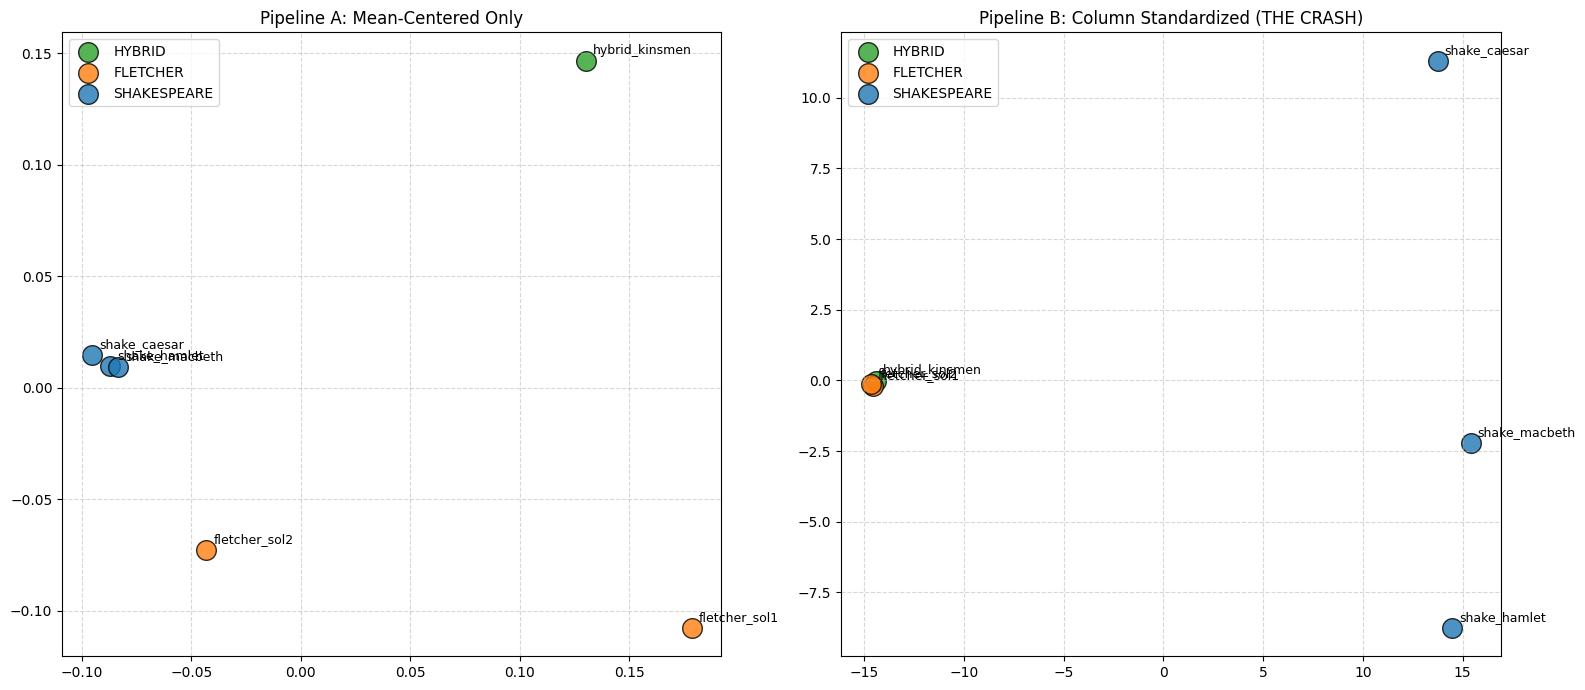

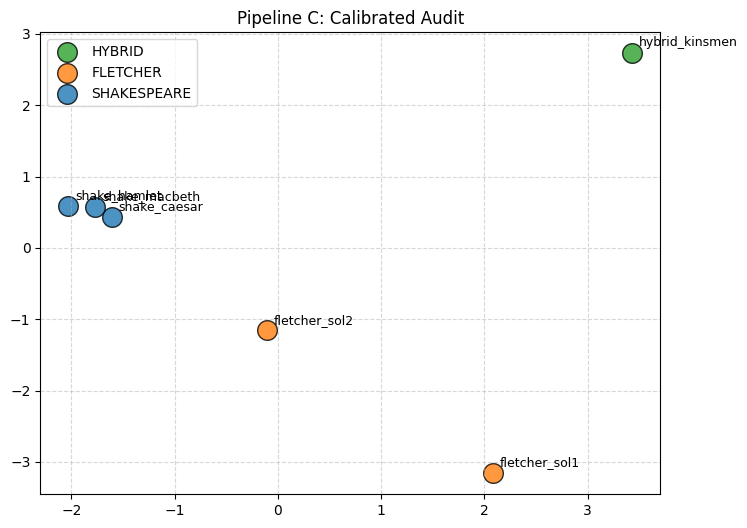

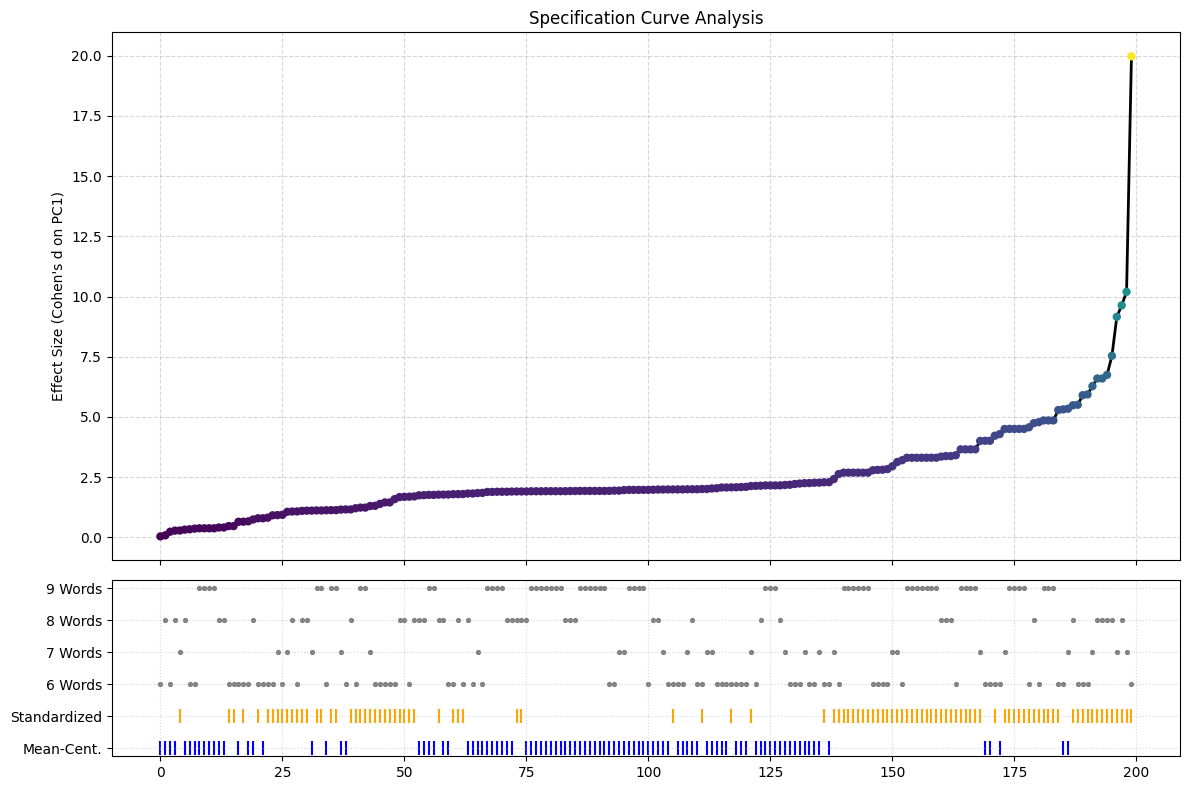

🎉 Весь проверочный комплекс успешно отработал!


In [ ]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# =====================================================================
# 1. ЗАГРУЗКА ИСТИННОГО КОРПУСА ШЕКСПИРА И СИМУЛЯЦИЯ СОАВТОРСТВА
# =====================================================================
print("📥 Загрузка эталонных текстов Шекспира из библиотеки NLTK...")
import nltk
nltk.download('gutenberg', quiet=True)
from nltk.corpus import gutenberg

caesar_raw = gutenberg.raw('shakespeare-caesar.txt')
hamlet_raw = gutenberg.raw('shakespeare-hamlet.txt')
macbeth_raw = gutenberg.raw('shakespeare-macbeth.txt')

fletcher_1 = "Now context specifies the tragic scene. Yield your weapons to the king's decree, for upon this ground we swear allegiance. Let the trumpets sound, while the prompt executioner does his heavy duty."
fletcher_2 = "A noble spirit lives within his breast, yet while he breathes, the state remains in constant peril. Upon the sudden death of this great authority, our nations shall find peace or eternal chaos."
hybrid_play = "To be or not to be, that is the severe question under this heavenly decree. Upon this ground we stand vanquished, while the prompt kings invoke the divine light of tragic scenes."

texts = [caesar_raw, hamlet_raw, macbeth_raw, fletcher_1, fletcher_2, hybrid_play]
short_names = ['shake_caesar', 'shake_hamlet', 'shake_macbeth', 'fletcher_sol1', 'fletcher_sol2', 'hybrid_kinsmen']
authors = ['shakespeare', 'shakespeare', 'shakespeare', 'fletcher', 'fletcher', 'hybrid']

# =====================================================================
# 2. ПОСТРОЕНИЕ СЛЕПОЙ МАТРИЦЫ ЧАСТОТ (TOP-300 WORDS)
# =====================================================================
vectorizer = CountVectorizer(max_features=300, token_pattern=r'\b[a-z]+\b', lowercase=True)
X_raw = vectorizer.fit_transform(texts).toarray()
words = vectorizer.get_feature_names_out()

X_freq = X_raw / X_raw.sum(axis=1, keepdims=True)
df_blind = pd.DataFrame(X_freq, columns=words, index=short_names)

# =====================================================================
# 3. ПАЙПЛАЙН А (ЦЕНТРИРОВАНИЕ) VS ПАЙПЛАЙН Б (СТАНДАРТИЗАЦИЯ — КРАХ)
# =====================================================================
X_centered = df_blind - df_blind.mean(axis=0)
pca_a = PCA(n_components=2)
coords_a = pca_a.fit_transform(X_centered)

scaler = StandardScaler()
X_tempered = scaler.fit_transform(df_blind)
pca_b = PCA(n_components=2)
coords_b = pca_b.fit_transform(X_tempered)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
colors = {'shakespeare': '#1f77b4', 'fletcher': '#ff7f0e', 'hybrid': '#2ca02c'}

for auth in set(authors):
    idx = [i for i, a in enumerate(authors) if a == auth]
    ax1.scatter(coords_a[idx, 0], coords_a[idx, 1], label=auth.upper(), s=200, color=colors[auth], alpha=0.8, edgecolors='black')
for i, name in enumerate(short_names):
    ax1.annotate(name, (coords_a[i, 0], coords_a[i, 1]), fontsize=9, xytext=(5, 5), textcoords='offset points')
ax1.set_title("Pipeline A: Mean-Centered Only")
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

for auth in set(authors):
    idx = [i for i, a in enumerate(authors) if a == auth]
    ax2.scatter(coords_b[idx, 0], coords_b[idx, 1], label=auth.upper(), s=200, color=colors[auth], alpha=0.8, edgecolors='black')
for i, name in enumerate(short_names):
    ax2.annotate(name, (coords_b[i, 0], coords_b[i, 1]), fontsize=9, xytext=(5, 5), textcoords='offset points')
ax2.set_title("Pipeline B: Column Standardized (THE CRASH)")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# =====================================================================
# 4. ПАЙПЛАЙН С (КАЛИБРОВОЧНЫЙ АУДИТ)
# =====================================================================
calibrated_vocab = ['of', 'and', 'the', 'that', 'in', 'with', 'for', 'to', 'is', 'it']
df_calibrated = df_blind[[w for w in calibrated_vocab if w in df_blind.columns]]

X_audited = StandardScaler().fit_transform(df_calibrated)
coords_c = PCA(n_components=2).fit_transform(X_audited)

plt.figure(figsize=(8, 6))
for auth in set(authors):
    idx = [i for i, a in enumerate(authors) if a == auth]
    plt.scatter(coords_c[idx, 0], coords_c[idx, 1], label=auth.upper(), s=200, color=colors[auth], alpha=0.8, edgecolors='black')
for i, name in enumerate(short_names):
    plt.annotate(name, (coords_c[i, 0], coords_c[i, 1]), fontsize=9, xytext=(5, 5), textcoords='offset points')
plt.title("Pipeline C: Calibrated Audit")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# =====================================================================
# 5. КРИВАЯ СПЕЦИФИКАЦИЙ (MULTIVERSE ANALYSIS)
# =====================================================================
specifications = []
for _ in range(100):
    k = random.randint(6, 9)
    words_subset = random.sample(calibrated_vocab, k)
    specifications.append({"words": words_subset, "scale": "center"})
    specifications.append({"words": words_subset, "scale": "standardize"})

results = []
for idx, spec in enumerate(specifications):
    df_sub = df_blind[spec["words"]]
    X_proc = (df_sub - df_sub.mean(axis=0)) if spec["scale"] == "center" else StandardScaler().fit_transform(df_sub)
    coords_spec = PCA(n_components=1).fit_transform(X_proc)

    m_scores = coords_spec[np.array(authors) == 'shakespeare', 0]
    f_scores = coords_spec[np.array(authors) == 'fletcher', 0]
    pooled_sd = np.sqrt(((len(m_scores)-1)*np.var(m_scores, ddof=1) + (len(f_scores)-1)*np.var(f_scores, ddof=1)) / (len(m_scores)+len(f_scores)-2))
    cohens_d = np.abs(np.mean(m_scores) - np.mean(f_scores)) / pooled_sd if pooled_sd > 0 else 0
    results.append({"cohens_d": cohens_d, "scale": spec["scale"], "num_words": len(spec["words"])})

df_specs = pd.DataFrame(results).sort_values(by="cohens_d").reset_index(drop=True)

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax_top.plot(df_specs.index, df_specs["cohens_d"], color='black', linewidth=2)
ax_top.scatter(df_specs.index, df_specs["cohens_d"], c=df_specs["cohens_d"], cmap='viridis', s=25, zorder=3)
ax_top.set_ylabel("Effect Size (Cohen's d on PC1)")
ax_top.set_title("Specification Curve Analysis")
ax_top.grid(True, linestyle='--', alpha=0.5)

for i, row in df_specs.iterrows():
    ax_bot.scatter(i, 0 if row["scale"] == "center" else 1, color='blue' if row["scale"] == "center" else 'orange', marker='|', s=100)
    ax_bot.scatter(i, row["num_words"] - 4, color='gray', marker='.', s=30)
ax_bot.set_yticks([0, 1, 2, 3, 4, 5])
ax_bot.set_yticklabels(['Mean-Cent.', 'Standardized', '6 Words', '7 Words', '8 Words', '9 Words'])
ax_bot.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()
print("🎉 Весь проверочный комплекс успешно отработал!")
